In [ ]:

# CodeWeakness AI
# Step 1: Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("CodeWeakness AI project started!")
print("Libraries imported successfully.")


CodeWeakness AI project started!
Libraries imported successfully.


In [ ]:

# Step 2: Create sample coding practice data

data = {
    "student_id": [
        101, 101, 101, 101, 101,
        102, 102, 102, 102, 102,
        103, 103, 103, 103, 103,
        104, 104, 104, 104, 104,
        105, 105, 105, 105, 105
    ],

    "topic": [
        "Arrays", "Strings", "Recursion", "Sorting", "Searching",
        "Arrays", "Strings", "Recursion", "Sorting", "Searching",
        "Arrays", "Strings", "Recursion", "Sorting", "Searching",
        "Arrays", "Strings", "Recursion", "Sorting", "Searching",
        "Arrays", "Strings", "Recursion", "Sorting", "Searching"
    ],

    "difficulty": [
        "Easy", "Easy", "Medium", "Medium", "Easy",
        "Easy", "Medium", "Hard", "Medium", "Easy",
        "Medium", "Easy", "Hard", "Hard", "Medium",
        "Easy", "Medium", "Medium", "Easy", "Easy",
        "Medium", "Hard", "Hard", "Medium", "Easy"
    ],

    "attempts": [
        2, 3, 5, 2, 1,
        1, 4, 7, 3, 2,
        3, 2, 8, 5, 3,
        1, 5, 4, 2, 1,
        4, 6, 9, 4, 2
    ],

    "correct": [
        1, 0, 0, 1, 1,
        1, 0, 0, 1, 1,
        0, 1, 0, 0, 1,
        1, 0, 1, 1, 1,
        0, 0, 0, 1, 1
    ]
}

df = pd.DataFrame(data)

print("Dataset created successfully!")
display(df.head(10))


Dataset created successfully!


,student_id,topic,difficulty,attempts,correct
0,101,Arrays,Easy,2,1
1,101,Strings,Easy,3,0
2,101,Recursion,Medium,5,0
3,101,Sorting,Medium,2,1
4,101,Searching,Easy,1,1
5,102,Arrays,Easy,1,1
6,102,Strings,Medium,4,0
7,102,Recursion,Hard,7,0
8,102,Sorting,Medium,3,1
9,102,Searching,Easy,2,1


In [ ]:

# Step 3: Explore the dataset

print("Dataset shape:", df.shape)

print("\nColumn information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nOverall correctness rate:")
print(round(df["correct"].mean() * 100, 2), "%")

print("\nAverage attempts by topic:")
print(df.groupby("topic")["attempts"].mean().round(2))


Dataset shape: (25, 5)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   student_id  25 non-null     int64 
 1   topic       25 non-null     object
 2   difficulty  25 non-null     object
 3   attempts    25 non-null     int64 
 4   correct     25 non-null     int64 
dtypes: int64(3), object(2)
memory usage: 1.1+ KB

Missing values:
student_id    0
topic         0
difficulty    0
attempts      0
correct       0
dtype: int64

Overall correctness rate:
56.0 %

Average attempts by topic:
topic
Arrays       2.2
Recursion    6.6
Searching    1.8
Sorting      3.2
Strings      4.0
Name: attempts, dtype: float64


In [ ]:

# CodeWeakness AI
# Step 2.1: Analyze coding performance by topic

topic_analysis = df.groupby("topic").agg(
    total_students=("student_id", "count"),
    correct_answers=("correct", "sum"),
    accuracy=("correct", "mean"),
    average_attempts=("attempts", "mean")
).reset_index()

topic_analysis["accuracy"] = (
    topic_analysis["accuracy"] * 100
).round(2)

topic_analysis["average_attempts"] = (
    topic_analysis["average_attempts"]
).round(2)

topic_analysis = topic_analysis.sort_values(
    by="accuracy",
    ascending=True
)

display(topic_analysis)


,topic,total_students,correct_answers,accuracy,average_attempts
1,Recursion,5,1,20.0,6.6
4,Strings,5,1,20.0,4.0
0,Arrays,5,3,60.0,2.2
3,Sorting,5,4,80.0,3.2
2,Searching,5,5,100.0,1.8


In [ ]:

# Step 2.2: Identify topics needing more practice

WEAKNESS_THRESHOLD = 60

topic_analysis["status"] = topic_analysis["accuracy"].apply(
    lambda accuracy: (
        "Needs Practice"
        if accuracy < WEAKNESS_THRESHOLD
        else "Good Progress"
    )
)

print("CODING WEAKNESS REPORT")
print("=" * 35)

for _, row in topic_analysis.iterrows():
    print(
        f"{row['topic']}: {row['accuracy']}% accuracy "
        f"| {row['status']}"
    )

weak_topics = topic_analysis[
    topic_analysis["status"] == "Needs Practice"
]

print("\nTopics to prioritize:")

if not weak_topics.empty:
    for topic in weak_topics["topic"]:
        print("-", topic)
else:
    print("No topics below the threshold.")


CODING WEAKNESS REPORT
Recursion: 20.0% accuracy | Needs Practice
Strings: 20.0% accuracy | Needs Practice
Arrays: 60.0% accuracy | Good Progress
Sorting: 80.0% accuracy | Good Progress
Searching: 100.0% accuracy | Good Progress

Topics to prioritize:
- Recursion
- Strings


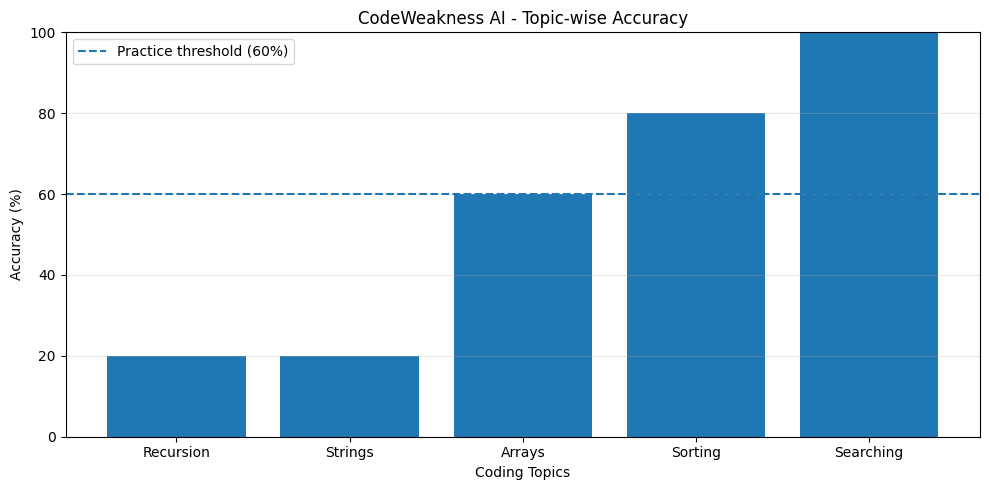

In [ ]:

# Step 2.3: Plot topic-wise accuracy

plt.figure(figsize=(10, 5))

bars = plt.bar(
    topic_analysis["topic"],
    topic_analysis["accuracy"]
)

plt.axhline(
    y=WEAKNESS_THRESHOLD,
    linestyle="--",
    label="Practice threshold (60%)"
)

plt.title("CodeWeakness AI - Topic-wise Accuracy")
plt.xlabel("Coding Topics")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

# Step 2.4: Recommend topics to practice

recommendations = {
    "Arrays": "Practice traversal, searching, and two-pointer problems.",
    "Strings": "Practice string manipulation, palindrome, and frequency problems.",
    "Recursion": "Practice base cases, recursive calls, and factorial problems.",
    "Sorting": "Practice bubble sort, selection sort, and merge sort.",
    "Searching": "Practice linear search and binary search."
}

print("YOUR PRACTICE PLAN")
print("=" * 35)

for _, row in topic_analysis.iterrows():
    if row["status"] == "Needs Practice":
        print(f"\nTopic: {row['topic']}")
        print(f"Accuracy: {row['accuracy']}%")
        print(
            "Recommendation:",
            recommendations.get(
                row["topic"],
                "Practice fundamental problems."
            )
        )


YOUR PRACTICE PLAN

Topic: Recursion
Accuracy: 20.0%
Recommendation: Practice base cases, recursive calls, and factorial problems.

Topic: Strings
Accuracy: 20.0%
Recommendation: Practice string manipulation, palindrome, and frequency problems.


In [ ]:

# Step 3.1: Prepare data for Machine Learning

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Input features and target
X = df[["topic", "difficulty", "attempts"]]
y = df["correct"]

print("Features:")
display(X.head())

print("\nTarget labels:")
print(y.head())


Features:


,topic,difficulty,attempts
0,Arrays,Easy,2
1,Strings,Easy,3
2,Recursion,Medium,5
3,Sorting,Medium,2
4,Searching,Easy,1



Target labels:
0    1
1    0
2    0
3    1
4    1
Name: correct, dtype: int64


In [ ]:

# Step 3.2: Split data and train the model

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            ["topic", "difficulty"]
        )
    ],
    remainder="passthrough"
)

model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            class_weight="balanced"
        )
    )
])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Random Forest model trained successfully!
Training records: 17
Testing records: 8


Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

   Incorrect       1.00      1.00      1.00         4
     Correct       1.00      1.00      1.00         4

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8



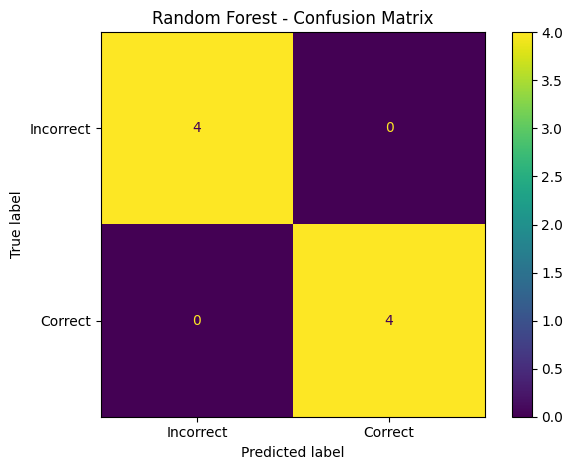

In [ ]:

# Step 3.3: Evaluate model performance

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Incorrect", "Correct"],
        zero_division=0
    )
)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Incorrect", "Correct"]
).plot()

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

# Step 3.4: Test the trained model on a sample

sample = pd.DataFrame([{
    "topic": "Recursion",
    "difficulty": "Hard",
    "attempts": 5
}])

prediction = model.predict(sample)[0]
probabilities = model.predict_proba(sample)[0]

print("Topic:", sample.loc[0, "topic"])
print("Difficulty:", sample.loc[0, "difficulty"])
print("Attempts:", sample.loc[0, "attempts"])
print(
    "Predicted outcome:",
    "Correct" if prediction == 1 else "Incorrect"
)
print(
    "Model probability of correct outcome:",
    round(probabilities[list(model.classes_).index(1)] * 100, 2),
    "%"
)


Topic: Recursion
Difficulty: Hard
Attempts: 5
Predicted outcome: Incorrect
Model probability of correct outcome: 14.0 %


In [12]:
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [13]:
X = df[["topic", "difficulty", "attempts"]]
y = df["correct"]

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         ["topic", "difficulty"]),
        ("numeric", StandardScaler(), ["attempts"])
    ]
)

X_processed = preprocessor.fit_transform(X)
X_processed = X_processed.astype("float32")

X_train, X_test, y_train, y_test = train_test_split(
    X_processed,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of input features:", X_train.shape[1])

Training samples: 17
Testing samples: 8
Number of input features: 9


In [14]:
tf.random.set_seed(42)

dl_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

dl_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = dl_model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=4,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 195ms/step - accuracy: 0.1765 - loss: 0.7546 - val_accuracy: 0.2500 - val_loss: 0.7209
Epoch 2/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.4118 - loss: 0.7116 - val_accuracy: 0.3750 - val_loss: 0.7162
Epoch 3/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.3529 - loss: 0.7262 - val_accuracy: 0.3750 - val_loss: 0.7112
Epoch 4/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.5882 - loss: 0.6810 - val_accuracy: 0.3750 - val_loss: 0.7059
Epoch 5/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4118 - loss: 0.7142 - val_accuracy: 0.3750 - val_loss: 0.7009
Epoch 6/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5294 - loss: 0.6822 - val_accuracy: 0.3750 - val_loss: 0.6953
Epoch 7/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4706 - loss: 0.6759 - val_accuracy: 0.3750 - val_loss: 0.6890
Epoch 8/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4118 - loss: 0.6999 - val_accuracy: 0.5000 - val_loss: 0.6829

In [15]:
loss, accuracy = dl_model.evaluate(X_test, y_test, verbose=0)

print("Test Loss:", round(loss, 4))
print("Test Accuracy:", round(accuracy * 100, 2), "%")

Test Loss: 0.5432
Test Accuracy: 100.0 %


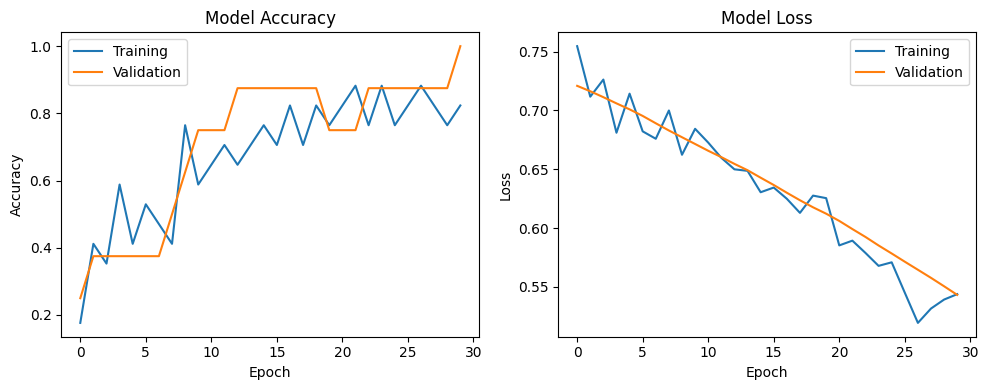

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Analyse student performance by topic
topic_analysis = df.groupby("topic").agg(
    total_attempts=("correct", "count"),
    correct_answers=("correct", "sum"),
    accuracy=("correct", "mean"),
    average_attempts=("attempts", "mean")
).reset_index()

topic_analysis["accuracy"] = (
    topic_analysis["accuracy"] * 100
).round(2)

topic_analysis["average_attempts"] = (
    topic_analysis["average_attempts"]
).round(2)

# Identify weak topics
def identify_status(accuracy):
    if accuracy < 60:
        return "Needs Practice"
    return "Good Progress"

topic_analysis["status"] = topic_analysis["accuracy"].apply(
    identify_status
)

# Sort weakest topics first
topic_analysis = topic_analysis.sort_values("accuracy")

print("CODEWEAKNESS AI - STUDENT PERFORMANCE DASHBOARD")
print("=" * 55)

display(topic_analysis)

weak_topics = topic_analysis[
    topic_analysis["status"] == "Needs Practice"
]

print("\nTopics that need more practice:")
if len(weak_topics) > 0:
    for topic in weak_topics["topic"]:
        print("-", topic)
else:
    print("No weak topics identified using the current threshold.")

CODEWEAKNESS AI - STUDENT PERFORMANCE DASHBOARD


,topic,total_attempts,correct_answers,accuracy,average_attempts,status
1,Recursion,5,1,20.0,6.6,Needs Practice
4,Strings,5,1,20.0,4.0,Needs Practice
0,Arrays,5,3,60.0,2.2,Good Progress
3,Sorting,5,4,80.0,3.2,Good Progress
2,Searching,5,5,100.0,1.8,Good Progress



Topics that need more practice:
- Recursion
- Strings


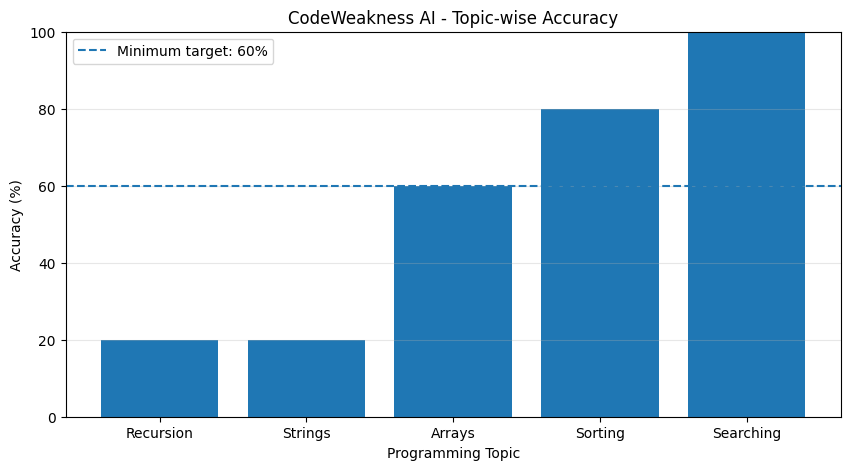

In [19]:
plt.figure(figsize=(10, 5))

plt.bar(
    topic_analysis["topic"],
    topic_analysis["accuracy"]
)

plt.axhline(
    y=60,
    linestyle="--",
    label="Minimum target: 60%"
)

plt.title("CodeWeakness AI - Topic-wise Accuracy")
plt.xlabel("Programming Topic")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

In [20]:
recommendations = {
    "Arrays": "Practise array traversal, searching, and two-pointer problems.",
    "Strings": "Practise string manipulation, palindrome checks, and character frequency.",
    "Recursion": "Start with factorial and Fibonacci, then solve recursion problems.",
    "Sorting": "Revise bubble sort, selection sort, insertion sort, and merge sort.",
    "Searching": "Practise linear search, binary search, and boundary conditions."
}

print("PERSONALIZED PRACTICE PLAN")
print("=" * 40)

for _, row in topic_analysis.iterrows():
    if row["status"] == "Needs Practice":
        print(f"\nTopic: {row['topic']}")
        print(f"Accuracy: {row['accuracy']}%")
        print(f"Recommendation: {recommendations.get(row['topic'], 'Practise basic problems.')}")

PERSONALIZED PRACTICE PLAN

Topic: Recursion
Accuracy: 20.0%
Recommendation: Start with factorial and Fibonacci, then solve recursion problems.

Topic: Strings
Accuracy: 20.0%
Recommendation: Practise string manipulation, palindrome checks, and character frequency.


In [21]:
topic_analysis.to_csv(
    "codeweakness_topic_report.csv",
    index=False
)

print("Report saved successfully!")

Report saved successfully!


In [22]:
from google.colab import files
files.download("codeweakness_topic_report.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
!pip -q install gradio

In [24]:
import gradio as gr
import pandas as pd

def analyze_performance(topic, difficulty, attempts):
    # Prepare the user's input
    sample = pd.DataFrame([{
        "topic": topic,
        "difficulty": difficulty,
        "attempts": int(attempts)
    }])

    # Predict the outcome using the ML model
    prediction = model.predict(sample)[0]
    probabilities = model.predict_proba(sample)[0]

    correct_index = list(model.classes_).index(1)
    correct_probability = probabilities[correct_index] * 100

    # Find the topic's historical accuracy in the sample dataset
    topic_data = topic_analysis[
        topic_analysis["topic"] == topic
    ]

    topic_accuracy = float(topic_data["accuracy"].iloc[0])

    if topic_accuracy < 60:
        status = "Needs Practice"
    else:
        status = "Good Progress"

    recommendation = recommendations.get(
        topic,
        "Practise basic problems for this topic."
    )

    result = f"""
## CodeWeakness AI Report

**Topic:** {topic}

**Difficulty:** {difficulty}

**Attempts:** {int(attempts)}

**Historical topic accuracy:** {topic_accuracy}%

**Topic status:** {status}

**ML model prediction for this attempt:** {"Correct" if prediction == 1 else "Incorrect"}

**Model-estimated probability of a correct answer:** {correct_probability:.1f}%

### Recommended Practice
{recommendation}
"""

    return result


demo = gr.Interface(
    fn=analyze_performance,
    inputs=[
        gr.Dropdown(
            choices=["Arrays", "Strings", "Recursion", "Sorting", "Searching"],
            label="Programming Topic",
            value="Arrays"
        ),
        gr.Dropdown(
            choices=["Easy", "Medium", "Hard"],
            label="Difficulty",
            value="Easy"
        ),
        gr.Slider(
            minimum=1,
            maximum=10,
            value=3,
            step=1,
            label="Number of Attempts"
        )
    ],
    outputs=gr.Markdown(label="Performance Report"),
    title="CodeWeakness AI",
    description=(
        "Analyze coding practice performance and discover "
        "which programming topics need more attention."
    )
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ecb2e9150d43166faf.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [25]:
%%writefile requirements.txt
pandas
numpy
matplotlib
scikit-learn
tensorflow
gradio

Writing requirements.txt


In [26]:

%%writefile README.md
# CodeWeakness AI

An AI-based coding practice analysis system that identifies
programming topics requiring improvement and recommends
targeted practice activities.

## Features

- Topic-wise coding performance analysis
- Identification of topics needing more practice
- Machine Learning classification using Random Forest
- Deep Learning demonstration using a Neural Network
- Performance visualizations
- Personalized practice recommendations
- Interactive Gradio web interface
- CSV report generation

## Technologies Used

- Python
- Pandas and NumPy
- Matplotlib
- Scikit-learn
- TensorFlow and Keras
- Gradio
- Google Colab

## Programming Topics

- Arrays
- Strings
- Recursion
- Sorting
- Searching

## How to Run

1. Open `codeweakness_ai.ipynb` in Google Colab.
2. Run the notebook cells in order.
3. Launch the Gradio interface.
4. Enter the programming topic, difficulty, and number
   of attempts to view the generated report.

## Dataset

The initial dataset contains synthetic sample records
created for demonstrating the project workflow.
It does not represent real student performance.

## Limitations

The initial dataset is small and synthetic. Model
predictions are experimental and should not be treated
as reliable assessments of coding ability.

## Future Improvements

- Collect real, consented coding practice data
- Track individual student progress over time
- Improve model evaluation with a larger dataset
- Add user accounts and progress history
- Recommend practice questions based on weak topics

## Author

B.Tech Artificial Intelligence and Data Science Student


Writing README.md


In [27]:
from google.colab import files

files.download("README.md")
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>